# Sugeno (TSK) Fuzzy System

**Goal.** Replace the fuzzy conclusions of Mamdani with simple mathematical functions.

**Rules.** `IF AT is low AND V is high THEN z = p*AT + q*V + r`

**Output.** A weighted average, with no defuzzification step:

$$z = \frac{\sum_i w_i z_i}{\sum_i w_i}$$

For fixed membership functions, the output is **linear in the consequent parameters**, so they can be found exactly by least squares.
We compare two types: *zero-order* (each rule outputs a constant) and *first-order* (each rule outputs a linear function).


**The dataset.** *Combined Cycle Power Plant* (UCI): 9,568 hourly records. Inputs: ambient temperature `AT`, exhaust vacuum `V`,
ambient pressure `AP`, humidity `RH`. Output: electrical power `PE` in MW.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi",
    "openpyxl": "openpyxl"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "ccpp"
archive = download("https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Already downloaded: data\ccpp\dataset.zip
Files: ['dataset.zip', 'Folds5x2_pp.ods', 'Folds5x2_pp.xlsx', 'Readme.txt', 'Readme.txt~']


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_excel(DATA_DIR / "CCPP" / "Folds5x2_pp.xlsx", sheet_name=0)
# The same split (seed 42, 20% test) as the linear regression notebook, so results can be compared.
train, test = train_test_split(df, test_size=0.2, random_state=SEED)
print("Train:", train.shape, "Test:", test.shape)

Train: (7654, 5) Test: (1914, 5)


## 2. Rule strengths
Three Gaussian membership functions per input and nine rules, in the same spirit as the Mamdani system. They are not trained here.

In [5]:
def gaussian(x, center, sigma):
    return np.exp(-((x - center) ** 2) / (2 * sigma ** 2))

def anchors(column):
    """Centers at the 10th, 50th and 90th percentiles of the training data."""
    centers = np.percentile(train[column], [10, 50, 90])
    return centers, np.full(3, (centers[-1] - centers[0]) / 4)

at_c, at_s = anchors("AT")
v_c, v_s = anchors("V")

def normalized_strengths(AT, V):
    """Product AND for all 9 rules, then normalization so that the strengths sum to 1."""
    mu_at = gaussian(AT[:, None], at_c, at_s)   # shape (samples, 3)
    mu_v = gaussian(V[:, None], v_c, v_s)
    w = (mu_at[:, :, None] * mu_v[:, None, :]).reshape(len(AT), -1)
    return w / w.sum(axis=1, keepdims=True).clip(1e-12)

# Inputs are scaled so that the least-squares problem is well conditioned.
at_mean, at_std, v_mean, v_std = train.AT.mean(), train.AT.std(), train.V.mean(), train.V.std()
def inputs_of(frame):
    return frame.AT.to_numpy(), frame.V.to_numpy(), (frame.AT.to_numpy() - at_mean) / at_std, (frame.V.to_numpy() - v_mean) / v_std

## 3. Fit the consequent parameters
Each row of the matrix `A` is the Sugeno output written as coefficients of the unknown parameters.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    return rmse, float(mean_absolute_error(y_true, y_pred)), float(r2_score(y_true, y_pred))

def design(frame, order):
    at_raw, v_raw, at_z, v_z = inputs_of(frame)
    w = normalized_strengths(at_raw, v_raw)
    return w if order == 0 else np.hstack([w * at_z[:, None], w * v_z[:, None], w])

fitted = {}
for order in (0, 1):
    theta = np.linalg.lstsq(design(train, order), train.PE.to_numpy(), rcond=None)[0]
    fitted[order] = (theta, design(test, order) @ theta)
    r = report(test.PE, fitted[order][1])
    print(f"Order {order}: parameters = {theta.size:2d} | RMSE = {r[0]:.2f} MW | MAE = {r[1]:.2f} MW | R2 = {r[2]:.4f}")

theta_1, y_pred = fitted[1]
rmse, mae, r2 = report(test.PE, y_pred)
rmse_0 = report(test.PE, fitted[0][1])[0]

Order 0: parameters =  9 | RMSE = 4.75 MW | MAE = 3.72 MW | R2 = 0.9223
Order 1: parameters = 27 | RMSE = 4.43 MW | MAE = 3.48 MW | R2 = 0.9324


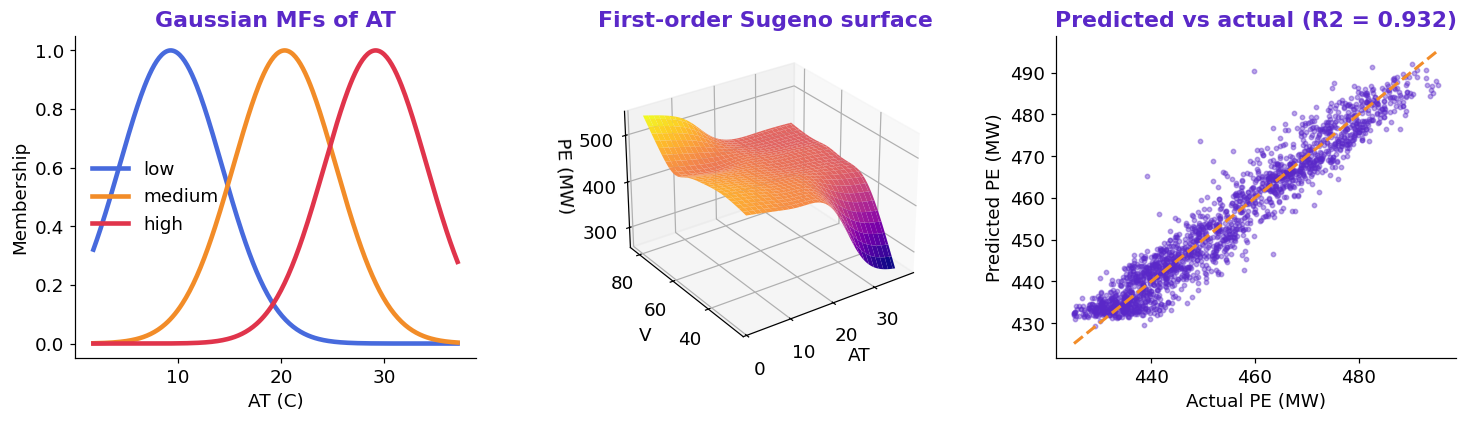

In [7]:
A, B = np.meshgrid(np.linspace(df.AT.min(), df.AT.max(), 60), np.linspace(df.V.min(), df.V.max(), 60))
grid = pd.DataFrame({"AT": A.ravel(), "V": B.ravel()})
surface = (design(grid, 1) @ theta_1).reshape(A.shape)
axis = np.linspace(df.AT.min(), df.AT.max(), 300)

fig = plt.figure(figsize=(13.5, 4))
ax1 = fig.add_subplot(1, 3, 1)
for i, (name, color) in enumerate(zip(("low", "medium", "high"), (BLUE, ORANGE, RED))):
    ax1.plot(axis, gaussian(axis, at_c[i], at_s[i]), color=color, lw=3, label=name)
ax1.set(title="Gaussian MFs of AT", xlabel="AT (C)", ylabel="Membership")
ax1.legend()

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
ax2.plot_surface(A, B, surface, cmap="plasma", lw=0)
ax2.set(title="First-order Sugeno surface", xlabel="AT", ylabel="V", zlabel="PE (MW)")
ax2.view_init(28, -125)

ax3 = fig.add_subplot(1, 3, 3)
ax3.scatter(test.PE, y_pred, s=8, alpha=0.4, color=PURPLE)
limits = [test.PE.min(), test.PE.max()]
ax3.plot(limits, limits, "--", color=ORANGE, lw=2)
ax3.set(title=f"Predicted vs actual (R2 = {r2:.3f})", xlabel="Actual PE (MW)", ylabel="Predicted PE (MW)")
fig.tight_layout()
plt.show()

In [8]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "02_sugeno.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Sugeno (TSK) fuzzy system",
    "dataset": "Combined Cycle Power Plant (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"RMSE (MW)": round(rmse, 2), "MAE (MW)": round(mae, 2), "R2": round(r2, 4), "RMSE zero-order (MW)": round(rmse_0, 2), "Rules": 9, "Parameters": int(theta_1.size)},
}
(results_dir / "02_sugeno.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Sugeno (TSK) fuzzy system",
  "dataset": "Combined Cycle Power Plant (UCI)",
  "n_samples": 9568,
  "metrics": {
    "RMSE (MW)": 4.43,
    "MAE (MW)": 3.48,
    "R2": 0.9324,
    "RMSE zero-order (MW)": 4.75,
    "Rules": 9,
    "Parameters": 27
  }
}


## What to remember
- Sugeno is cheap to compute and its consequents can be learned exactly.
- The premise part (the membership functions) stayed fixed here. Learning it as well is exactly what ANFIS adds.